# 05 — From model to points-based scorecard

The logistic regression gives each customer a probability of default. A **scorecard** expresses the same model as **points**:
each answer earns a number of points, and the points add up to a score. Banks use points because:
- anyone can read a scorecard and add up a score by hand. No formula is needed to explain a decision;
- the score has a fixed meaning: the same score always means the same odds, whatever the model;
- reason codes ("you lost most points on recent arrears") come straight from the table.

Run notebooks 02 and 04 first; this one uses the saved binnings and model coefficients.

In [1]:
import logging

import pandas as pd
import matplotlib.pyplot as plt

from scorecard.binning import load_binnings
from scorecard.data import MODELS_DIR, PROCESSED_DIR, REPORTS_DIR
from scorecard.plots import plot_score_distribution
from scorecard.scaling import (
    BASE_ODDS,
    BASE_SCORE,
    PDO,
    build_scorecard,
    check_score_pd_agreement,
    customer_breakdown,
    points_spread,
    score_band_table,
    score_customers,
    score_range,
    score_to_pd,
    scaling_constants,
)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)

coefficients = pd.read_csv(REPORTS_DIR / "model_coefficients.csv")
binning_tables = pd.read_csv(REPORTS_DIR / "binning_tables.csv")
binnings = load_binnings(MODELS_DIR / "binnings.pkl")
test = pd.read_csv(PROCESSED_DIR / "test.csv")
test_pd = pd.read_csv(PROCESSED_DIR / "test_pd.csv")
assert (test["id"].values == test_pd["id"].values).all()

## 1. Choosing the scale

Three settings define the scale:

| Setting | Value | Meaning |
|---|---|---|
| Base score | 600 | an anchor point on the scale |
| Base odds | 50 | at 600 points, there are 50 good customers for every bad one (PD = 1/51 ≈ 2%) |
| PDO | 20 | "points to double the odds": every +20 points doubles the odds of being good |

So 620 means odds of 100:1, 580 means 25:1 and 560 means 12.5:1. Each 20 points is one "halving or doubling" of risk.
These are common industry choices. Their only job is to give the score a fixed, interpretable meaning.

From them:
- **Factor** = PDO ÷ ln(2), the number of points per unit of log-odds;
- **Offset** = 600 − Factor × ln(50), which pins 600 to odds of 50.

In [2]:
factor, offset = scaling_constants(BASE_SCORE, BASE_ODDS, PDO)
logging.info("Factor = %.4f, Offset = %.4f", factor, offset)

INFO root: Factor = 28.8539, Offset = 487.1229


## 2. Points per bin

The model says: log-odds of default = intercept + Σ coefficient × WoE. A score is a rescaled log-odds of being *good*, which is
the negative of that. So each bin earns

> points = −Factor × coefficient × WoE + (Offset − Factor × intercept) ÷ number of variables

- The first part rewards safe bins. Coefficients are negative, so a **higher WoE (safer) earns more points**.
- The second part shares out the intercept and offset **equally across the 9 variables**, so no single variable carries a
  big constant. Every bin's points are then of similar size, and the total adds up to the full score.
- Points are **rounded to whole numbers**, as on a real scorecard. That costs at most 0.5 points per variable.

In [3]:
scorecard = build_scorecard(coefficients, binning_tables, factor, offset)
scorecard.to_csv(REPORTS_DIR / "scorecard.csv", index=False)
lowest, highest = score_range(scorecard)
logging.info("Possible scores: %d to %d", lowest, highest)

INFO scorecard.scaling: Scorecard: 9 variables, 49 bins, possible scores 437 to 575


INFO root: Possible scores: 437 to 575


## 3. The scorecard

One block per variable. Find the customer's bin in each block, and add up the points.

In [4]:
(scorecard.set_index(["variable", "bin"])
    .style.format({"woe": "{:+.3f}"})
    .set_table_styles([{"selector": "th.level0", "props": "vertical-align: top; font-weight: bold;"},
                       {"selector": "td, th", "props": "padding: 2px 10px;"}]))

The gap between a variable's best and worst bin shows how much it can move a score: its **weight** in the scorecard.

In [5]:
points_spread(scorecard)

,variable,min_points,max_points,spread
0,pay_1,19,71,52
1,limit_bal,49,68,19
2,pay_amt2,52,70,18
3,max_delinquency_6m,49,65,16
4,pay_4,51,60,9
5,pay_amt1,55,63,8
6,pay_5,52,59,7
7,pay_6,53,59,6
8,months_zero_payment_6m,57,60,3


How to read it:
- **`pay_1` dominates.** Its points range from 19 (2+ months late in September) to 71: a 52-point swing, more than two doublings of the odds.
- **`limit_bal`, `pay_amt2` and `max_delinquency_6m` follow** with 16–19 points each.
- **The older months (`pay_4`–`pay_6`) and `months_zero_payment_6m` are worth only 3–9 points.** They fine-tune the score rather than drive it.
- **Something a reviewer will ask about:** in `pay_1`, "paid in full" (-1) earns **64** points but "revolving" (0) earns **71**.
  That isn't a mistake; it follows the data. Customers who paid in full defaulted *more* often (17%) than those revolving (13%), as found in the EDA.
  But it's counter-intuitive, and some banks would merge the two bins for a scorecard that "makes sense" to customers. Worth discussing in validation.
- **All possible scores are between 437 and 575, below the 600 anchor.** That's expected: 600 means a PD of about 2%,
  and almost nobody in this portfolio (22% default rate) is that safe. The anchor fixes the *meaning* of the scale; it isn't meant to be the average score.

## 4. Worked example: one real customer from the test set

Customer **23469** was 2 months behind on every payment from April to August, improved to 1 month late in September,
paid NT$5,000 in August but nothing in September, and has a NT$50,000 limit.

In [6]:
customer = test.loc[test["id"] == 23469].iloc[0]
breakdown = customer_breakdown(customer, scorecard, binnings)
breakdown.style.format({"value": "{:,.0f}", "woe": "{:+.3f}"})

,variable,value,bin,woe,points
0,pay_1,1,1,-0.605,47
1,max_delinquency_6m,2,>= 2,-1.132,49
2,pay_4,2,>= 1,-1.410,51
3,pay_5,2,>= 2,-1.509,52
4,pay_6,2,>= 2,-1.369,53
5,months_zero_payment_6m,3,>= 2,-0.508,57
6,limit_bal,"50,000",30001 to 70000,-0.283,55
7,pay_amt1,0,<= 0,-0.673,55
8,pay_amt2,"5,000",4101 to 5000,+0.226,60


In [7]:
total = int(breakdown["points"].sum())
model_pd = test_pd.loc[test_pd["id"] == 23469, "pd"].item()
pd.Series({
    "Total score": total,
    "PD implied by the score": f"{score_to_pd(total, factor, offset):.1%}",
    "PD from the logistic regression": f"{model_pd:.1%}",
    "Actually defaulted in October?": "yes" if customer["default"] == 1 else "no",
}).to_frame("customer 23469")

,customer 23469
Total score,479
PD implied by the score,57.0%
PD from the logistic regression,57.4%
Actually defaulted in October?,yes


- The customer loses points almost everywhere. September's status (1 month late) earns 47 out of a possible 71.
  Their long history of arrears (2+ months) costs points on `max_delinquency_6m` and `pay_4`–`pay_6`, and paying nothing in September costs more.
  The **NT$5,000 August payment** is their one above-average item (60 points).
- **479 points** means odds of good of about 0.75:1, a **PD of about 57%**, close to the model's own 57.4%. The small
  difference is rounding. This customer did default.
- Reason codes come straight from the table. The biggest gaps between this customer's points and the best possible points are
  `pay_1` (−24), `max_delinquency_6m` (−16) and `limit_bal` (−13).

## 5. Do scores and PDs agree for everyone?

For every test customer, the score's PD should match the model's PD, with any difference down to rounding only.
With 9 variables each rounded by at most 0.5 points, no score can be more than 4.5 points from the exact value.

In [8]:
test_scores = score_customers(test, scorecard, binnings)
largest_gap = check_score_pd_agreement(test_scores, test_pd["pd"], n_variables=scorecard["variable"].nunique(),
                                       factor=factor, offset=offset)
test_scores.describe().to_frame("test scores").T

INFO scorecard.scaling: Score and PD agree: largest gap 2.34 points (rounding allowance 4.5)


,count,mean,std,min,25%,50%,75%,max
test scores,9000.0,530.576444,29.922427,437.0,515.0,542.0,551.0,575.0


## 6. Score distribution: goods vs bads

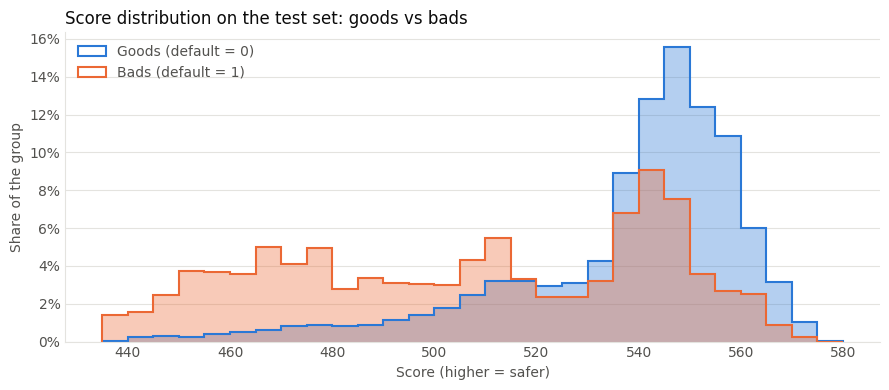

In [9]:
plot_score_distribution(test_scores, test["default"])
plt.show()

- **Goods** are concentrated at the top: about half of them sit between about 540 and 560.
- **Bads** spread across the whole range, with a long tail below 500, where almost everyone is a bad.
- **The overlap above 520** is the same limit we saw with PDs. Bads with a clean recent history score just like goods.
  That overlap is what Gini and KS will measure in validation.
- The scores are **lumpy** because a scorecard has a limited number of bin combinations. Many customers share exactly the same
  profile (e.g. "revolving every month, no arrears") and therefore the same score.

## 7. Score bands

In [10]:
bands = score_band_table(test_scores, test["default"], width=20)
bands.to_csv(REPORTS_DIR / "score_bands.csv", index=False)
bands.style.format({"customers": "{:,}", "bads": "{:,}", "bad_rate": "{:.1%}", "share": "{:.1%}",
                    "cumulative_share": "{:.1%}"})

,band,customers,bads,bad_rate,share,cumulative_share
0,420-439,32,28,87.5%,0.4%,0.4%
1,440-459,308,227,73.7%,3.4%,3.8%
2,460-479,546,350,64.1%,6.1%,9.8%
3,480-499,543,245,45.1%,6.0%,15.9%
4,500-519,"1,065",321,30.1%,11.8%,27.7%
5,520-539,"1,641",293,17.9%,18.2%,45.9%
6,540-559,"4,076",455,11.2%,45.3%,91.2%
7,560-579,789,72,9.1%,8.8%,100.0%


- **The bad rate falls in every band as the score rises**, from about 88% below 440 to about 9% at 560+. The ranking works, and
  that is the most important property of a scorecard.
- **Each 20-point band roughly halves the odds of default** up to about 540, as PDO = 20 intends.
  Example: 460–479 has 64% bads (odds of good about 0.6:1), 480–499 has 45% (about 1.2:1).
- **Almost half the customers (45%) fall in one band, 540–559.** These are the "revolving, never late" majority. A cut-off can't
  separate customers *within* that band, which limits how finely the bank can tune its strategy there.
- The bottom 16% of customers (scores below 500) contain about **43% of all bads**. That's the population a cut-off strategy would target first.